<div dir="rtl" style="text-align: right;">
گام اول: شناخت داده و کیفیت آن
</div>

### 1.

In [52]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

names_path = "census-income.names"
train_path = "census-income.data"
test_path = "census-income.test"

with open(names_path, "r", encoding="latin-1") as file:
    lines = file.readlines()

start = next(
    i for i, line in enumerate(lines)
    if line.strip().startswith("- 50000")
)

all_columns = []
numeric_features = []
categorical_features = []

for line in lines[start + 1:]:

    line = line.strip()

    if not line or line.startswith("|") or ":" not in line:
        continue

    name, definition = line.split(":", 1)

    name = name.strip()
    definition = definition.strip()

    all_columns.append(name)

    if name == "instance weight":
        continue

    if definition.lower().startswith("continuous"):
        numeric_features.append(name)
    else:
        categorical_features.append(name)

all_columns.append("income")

train_df = pd.read_csv(
    train_path,
    header=None,
    names=all_columns,
    skipinitialspace=True,
    na_values=["?"],
    keep_default_na=False
)

test_df = pd.read_csv(
    test_path,
    header=None,
    names=all_columns,
    skipinitialspace=True,
    na_values=["?"],
    keep_default_na=False
)

for df in [train_df, test_df]:
    object_columns = df.select_dtypes(include="str").columns
    df[object_columns] = df[object_columns].apply(
        lambda col: col.str.strip()
    )

weight_column = "instance weight"
target_column = "income"

feature_columns = [
    col for col in all_columns
    if col not in [weight_column, target_column]
]

print("Training Shape:", train_df.shape)
print("Test Shape:", test_df.shape)

print("\nNumber of Numerical Features:", len(numeric_features))
print("Number of Categorical Features:", len(categorical_features))
print("Number of Input Features:", len(feature_columns))

print("\nNumerical Features:")
print(numeric_features)

print("\nCategorical Features:")
print(categorical_features)


Training Shape: (199523, 42)
Test Shape: (99762, 42)

Number of Numerical Features: 7
Number of Categorical Features: 33
Number of Input Features: 40

Numerical Features:
['age', 'wage per hour', 'capital gains', 'capital losses', 'dividends from stocks', 'num persons worked for employer', 'weeks worked in year']

Categorical Features:
['class of worker', 'detailed industry recode', 'detailed occupation recode', 'education', 'enroll in edu inst last wk', 'marital stat', 'major industry code', 'major occupation code', 'race', 'hispanic origin', 'sex', 'member of a labor union', 'reason for unemployment', 'full or part time employment stat', 'tax filer stat', 'region of previous residence', 'state of previous residence', 'detailed household and family stat', 'detailed household summary in household', 'migration code-change in msa', 'migration code-change in reg', 'migration code-move within reg', 'live in this house 1 year ago', 'migration prev res in sunbelt', 'family members under 18',

In [53]:
data_summary = pd.DataFrame({
    "Training Data": [
        train_df.shape[0],
        train_df.shape[1],
        len(numeric_features),
        len(categorical_features),
        weight_column,
        target_column
    ],
    "Test Data": [
        test_df.shape[0],
        test_df.shape[1],
        len(numeric_features),
        len(categorical_features),
        weight_column,
        target_column
    ]
}, index=[
    "Number of Rows",
    "Number of Columns",
    "Numerical Features",
    "Categorical Features",
    "Sample Weight",
    "Target Variable"
])

display(data_summary)


,Training Data,Test Data
Number of Rows,199523,99762
Number of Columns,42,42
Numerical Features,7,7
Categorical Features,33,33
Sample Weight,instance weight,instance weight
Target Variable,income,income


### 2.

In [54]:
for df, dataset_name in [
    (train_df, "Training Data"),
    (test_df, "Test Data")
]:

    missing_report = pd.DataFrame({
        "Missing Count": df.isna().sum(),
        "Missing Percentage (%)": df.isna().mean() * 100
    })

    missing_report = missing_report.sort_values(
        by="Missing Count",
        ascending=False
    )

    print(f"\n{dataset_name}")
    display(missing_report.round(2))

    print("\nTop 5 Features with Most Missing Values:")
    display(missing_report.head(5).round(2))

    print(
        "\nTotal Missing Values:",
        df.isna().sum().sum()
    )

    print("-" * 60)


Training Data


,Missing Count,Missing Percentage (%)
migration prev res in sunbelt,99696,49.97
migration code-change in msa,99696,49.97
migration code-change in reg,99696,49.97
migration code-move within reg,99696,49.97
country of birth father,6713,3.36
country of birth mother,6119,3.07
country of birth self,3393,1.70
state of previous residence,708,0.35
age,0,0.00
class of worker,0,0.00



Top 5 Features with Most Missing Values:


,Missing Count,Missing Percentage (%)
migration prev res in sunbelt,99696,49.97
migration code-change in msa,99696,49.97
migration code-change in reg,99696,49.97
migration code-move within reg,99696,49.97
country of birth father,6713,3.36



Total Missing Values: 415717
------------------------------------------------------------

Test Data


,Missing Count,Missing Percentage (%)
migration prev res in sunbelt,49946,50.07
migration code-change in msa,49946,50.07
migration code-change in reg,49946,50.07
migration code-move within reg,49946,50.07
country of birth father,3429,3.44
country of birth mother,3072,3.08
country of birth self,1764,1.77
state of previous residence,330,0.33
age,0,0.00
class of worker,0,0.00



Top 5 Features with Most Missing Values:


,Missing Count,Missing Percentage (%)
migration prev res in sunbelt,49946,50.07
migration code-change in msa,49946,50.07
migration code-change in reg,49946,50.07
migration code-move within reg,49946,50.07
country of birth father,3429,3.44



Total Missing Values: 208379
------------------------------------------------------------


### 3.

In [55]:
y = train_df[target_column].astype("string").str.strip()

weights = pd.to_numeric(
    train_df[weight_column],
    errors="coerce"
)

class_counts = y.value_counts().sort_index()
class_percentages = class_counts / len(y) * 100

weighted_counts = weights.groupby(y).sum()
weighted_counts = weighted_counts.reindex(class_counts.index)

weighted_percentages = (
    weighted_counts / weights.sum()
) * 100

class_report = pd.DataFrame({
    "Count": class_counts,
    "Percentage (%)": class_percentages,
    "Weighted Count": weighted_counts,
    "Weighted Percentage (%)": weighted_percentages
})

display(class_report.round(2))


,Count,Percentage (%),Weighted Count,Weighted Percentage (%)
income,,,,
- 50000.,187141,93.79,3.250046e+08,93.59
50000+.,12382,6.21,2.224125e+07,6.41


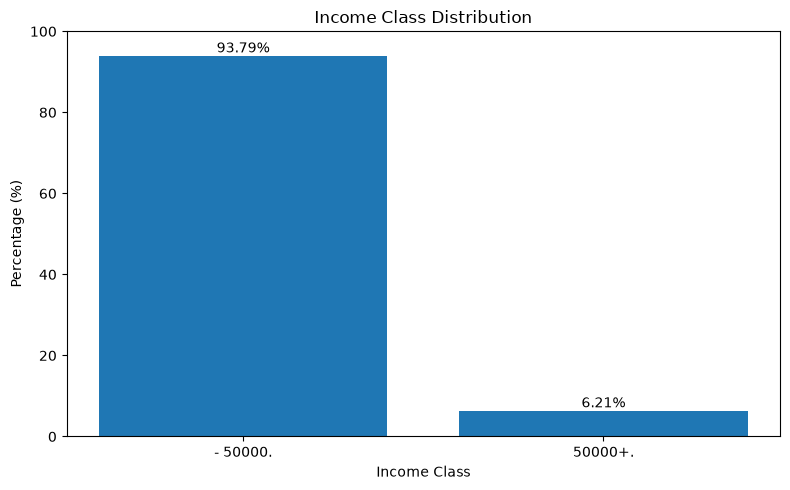

In [56]:
plt.figure(figsize=(8, 5))

plt.bar(
    class_counts.index,
    class_percentages.values
)

plt.title("Income Class Distribution")
plt.xlabel("Income Class")
plt.ylabel("Percentage (%)")

plt.ylim(0, 100)

for i, value in enumerate(class_percentages.values):
    plt.text(i, value + 1, f"{value:.2f}%", ha="center")

plt.tight_layout()
plt.show()


### 4.

In [57]:
duplicate_mask = train_df.duplicated(keep=False)

duplicate_records = duplicate_mask.sum()

duplicate_groups = (
    train_df.loc[duplicate_mask]
    .drop_duplicates()
    .shape[0]
)

conflict_mask = (
    train_df.groupby(
        feature_columns,
        dropna=False,
        sort=False
    )[target_column]
    .transform("nunique") > 1
)

conflict_records = conflict_mask.sum()

conflict_groups = (
    train_df.loc[conflict_mask, feature_columns]
    .drop_duplicates()
    .shape[0]
)

duplicate_report = pd.DataFrame({
    "Number of Records": [
        duplicate_records,
        conflict_records
    ],
    "Number of Groups": [
        duplicate_groups,
        conflict_groups
    ]
}, index=[
    "Completely Duplicate Records",
    "Same Features, Different Labels"
])

display(duplicate_report)


,Number of Records,Number of Groups
Completely Duplicate Records,5995,2766
"Same Features, Different Labels",379,89


### 5.

In [58]:
not_universe_rows = []

for col in categorical_features:

    values = train_df[col].astype("string")

    count = values.str.contains(
        "Not in universe",
        regex=False,
        na=False
    ).sum()

    missing_count = train_df[col].isna().sum()

    if count > 0:
        not_universe_rows.append({
            "Feature": col,
            "Not in universe Count": count,
            "Missing Count": missing_count,
            "Not in universe Percentage (%)":
                count / len(train_df) * 100
        })

not_universe_report = pd.DataFrame(not_universe_rows)

not_universe_report = not_universe_report.sort_values(
    by="Not in universe Count",
    ascending=False
)

display(not_universe_report.round(2))


,Feature,Not in universe Count,Missing Count,Not in universe Percentage (%)
14,fill inc questionnaire for veteran's admin,197539,0,99.01
5,reason for unemployment,193453,0,96.96
1,enroll in edu inst last wk,186943,0,93.69
7,state of previous residence,183750,708,92.09
6,region of previous residence,183750,0,92.09
4,member of a labor union,180459,0,90.45
13,family members under 18,144232,0,72.29
11,live in this house 1 year ago,101212,0,50.73
2,major industry code,100684,0,50.46
3,major occupation code,100684,0,50.46


<div dir="rtl" style="text-align: right;">
گام دوم: پیش پردازش و مهندسی ویژگی
</div>

In [59]:
def normalize_target(series):

    cleaned = (
        series.astype("string")
        .str.strip()
        .str.replace(r"\s+", "", regex=True)
        .str.replace(r"\.+$", "", regex=True)
    )

    mapping = {
        "-50000": 0,
        "50000+": 1
    }

    unknown_labels = set(cleaned.dropna().unique()) - set(mapping)

    if unknown_labels:
        raise ValueError(f"Unknown labels found: {unknown_labels}")

    if cleaned.isna().any():
        raise ValueError("Missing target values found!")

    return cleaned.map(mapping).astype("int8")

train_df["income"] = normalize_target(train_df["income"])
test_df["income"] = normalize_target(test_df["income"])

print("Training Target Distribution:")
display(train_df["income"].value_counts())

print("\nTest Target Distribution:")
display(test_df["income"].value_counts())


Training Target Distribution:


income
0    187141
1     12382
Name: count, dtype: int64


Test Target Distribution:


income
0    93576
1     6186
Name: count, dtype: int64

### 2.

In [60]:
target_column = "income"
weight_column = "instance weight"

feature_columns = numeric_features + categorical_features

feature_table = pd.DataFrame({
    "Feature": feature_columns,
    "Type": [
        "Numerical" if col in numeric_features else "Categorical"
        for col in feature_columns
    ]
})

display(feature_table)

print("Total Input Features:", len(feature_columns))
print("Numerical Features:", len(numeric_features))
print("Categorical Features:", len(categorical_features))


,Feature,Type
0,age,Numerical
1,wage per hour,Numerical
2,capital gains,Numerical
3,capital losses,Numerical
4,dividends from stocks,Numerical
5,num persons worked for employer,Numerical
6,weeks worked in year,Numerical
7,class of worker,Categorical
8,detailed industry recode,Categorical
9,detailed occupation recode,Categorical


Total Input Features: 40
Numerical Features: 7
Categorical Features: 33


### 3,4,5

In [61]:
from sklearn.model_selection import train_test_split

train_sample = train_df.sample(
    n=10000,
    random_state=42
).copy()

test_sample = test_df.sample(
    n=2000,
    random_state=43
).copy()

X = train_sample[feature_columns].copy()
y = train_sample[target_column].copy()

X_test = test_sample[feature_columns].copy()
y_test = test_sample[target_column].copy()

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)




Training: (8000, 40)
Validation: (2000, 40)
Test: (2000, 40)


In [62]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(
        strategy="constant",
        fill_value="Missing"
    )),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])


In [63]:
X_train_processed = preprocessor.fit_transform(X_train)
X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)

print("Preprocessing Completed!")


Preprocessing Completed!


In [64]:
dimension_report = pd.DataFrame({
    "Samples": [
        X_train.shape[0],
        X_val.shape[0],
        X_test.shape[0]
    ],
    "Features Before": [
        X_train.shape[1],
        X_val.shape[1],
        X_test.shape[1]
    ],
    "Features After": [
        X_train_processed.shape[1],
        X_val_processed.shape[1],
        X_test_processed.shape[1]
    ]
}, index=[
    "Training",
    "Validation",
    "Test"
])

display(dimension_report)


,Samples,Features Before,Features After
Training,8000,40,495
Validation,2000,40,495
Test,2000,40,495


In [65]:
from scipy import sparse

def count_missing_values(data):

    if sparse.issparse(data):
        return np.isnan(data.data).sum()

    return np.isnan(data).sum()


print("Missing Values After Preprocessing:")
print("Training:", count_missing_values(X_train_processed))
print("Validation:", count_missing_values(X_val_processed))
print("Test:", count_missing_values(X_test_processed))


Missing Values After Preprocessing:
Training: 0
Validation: 0
Test: 0


<div dir="rtl" style="text-align: right;">
گام سوم: طبقه بندی نامتوازن
</div>

### 1.

In [66]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score

class_counts = y_train.value_counts().sort_index()

class_percentages = (
    y_train.value_counts(normalize=True).sort_index() * 100
)

class_summary = pd.DataFrame({
    "Count": class_counts,
    "Percentage (%)": class_percentages
})

display(class_summary)

majority_class = y_train.value_counts().idxmax()
minority_class = y_train.value_counts().idxmin()

print("Majority Class:", majority_class)
print("Minority Class:", minority_class)


majority_model = DummyClassifier(
    strategy="most_frequent"
)

majority_model.fit(X_train_processed, y_train)

y_pred_majority = majority_model.predict(X_val_processed)

majority_accuracy = accuracy_score(y_val, y_pred_majority)

print("Majority Classifier Accuracy (%):", round(majority_accuracy * 100, 2))

,Count,Percentage (%)
income,,
0,7506,93.825
1,494,6.175


Majority Class: 0
Minority Class: 1
Majority Classifier Accuracy (%): 93.85


### 2.

In [67]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    recall_score
)

majority_metrics = {
    "Accuracy": accuracy_score(y_val, y_pred_majority),

    "Balanced Accuracy": balanced_accuracy_score(
        y_val, y_pred_majority
    ),

    "Macro-F1": f1_score(
        y_val, y_pred_majority,
        average="macro",
        zero_division=0
    ),

    "Minority Recall": recall_score(
        y_val, y_pred_majority,
        pos_label=minority_class,
        zero_division=0
    )
}

majority_results = pd.DataFrame(
    [majority_metrics],
    index=["Majority Classifier"]
)

display(majority_results.round(4))

,Accuracy,Balanced Accuracy,Macro-F1,Minority Recall
Majority Classifier,0.9385,0.5,0.4841,0.0


### 3.

In [68]:
from sklearn.linear_model import LogisticRegression

normal_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

balanced_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

normal_model.fit(X_train_processed, y_train)

balanced_model.fit(X_train_processed, y_train)

y_pred_normal = normal_model.predict(X_val_processed)

y_pred_balanced = balanced_model.predict(X_val_processed)

In [69]:
def calculate_metrics(y_true, y_pred):

    return {
        "Accuracy": accuracy_score(y_true, y_pred),

        "Balanced Accuracy": balanced_accuracy_score(
            y_true, y_pred
        ),

        "Macro-F1": f1_score(
            y_true, y_pred,
            average="macro",
            zero_division=0
        ),

        "Minority Recall": recall_score(
            y_true, y_pred,
            pos_label=minority_class,
            zero_division=0
        )
    }


results = {
    "Majority Classifier": calculate_metrics(
        y_val, y_pred_majority
    ),

    "Logistic Regression": calculate_metrics(
        y_val, y_pred_normal
    ),

    "Logistic Regression (Balanced)": calculate_metrics(
        y_val, y_pred_balanced
    )
}

comparison_table = pd.DataFrame(results).T

display(comparison_table.round(4))

,Accuracy,Balanced Accuracy,Macro-F1,Minority Recall
Majority Classifier,0.9385,0.5000,0.4841,0.0000
Logistic Regression,0.9505,0.6849,0.7305,0.3821
Logistic Regression (Balanced),0.8725,0.8447,0.6838,0.8130


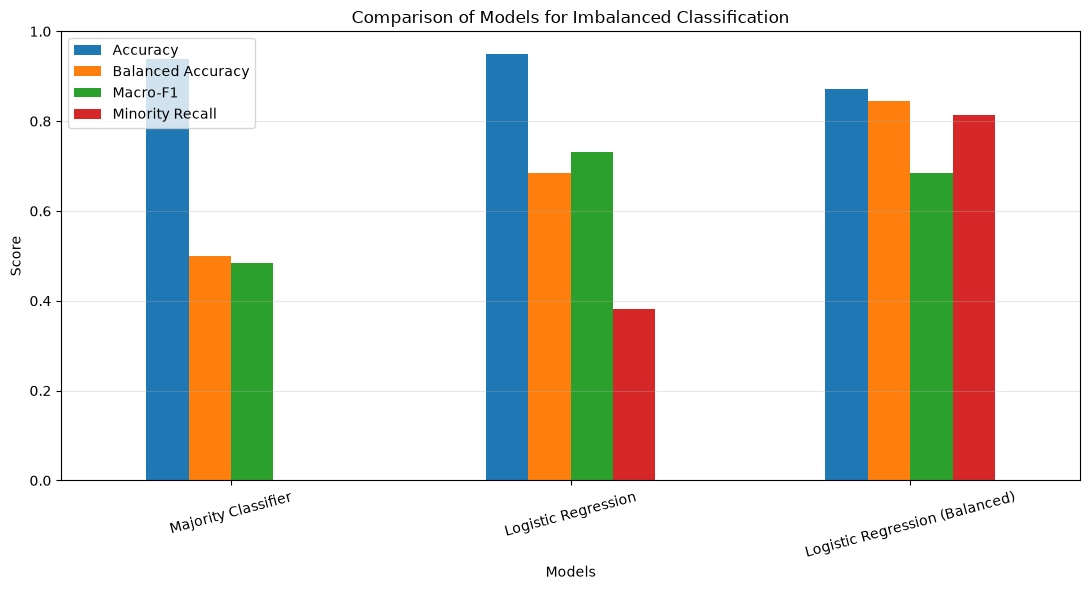

In [70]:
comparison_table.plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Comparison of Models for Imbalanced Classification")
plt.xlabel("Models")
plt.ylabel("Score")
plt.ylim(0, 1)

plt.xticks(rotation=15)
plt.legend(loc="best")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

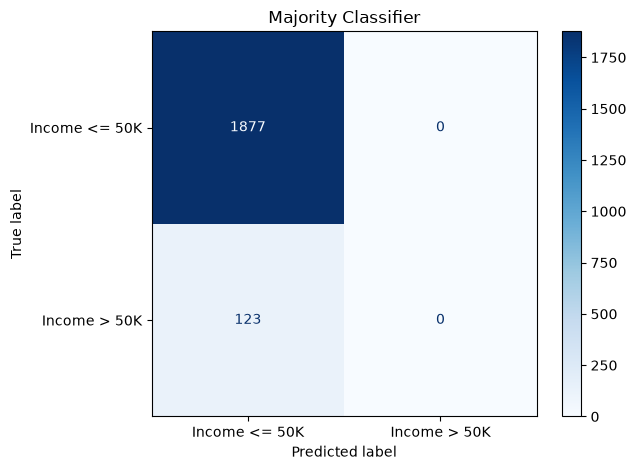

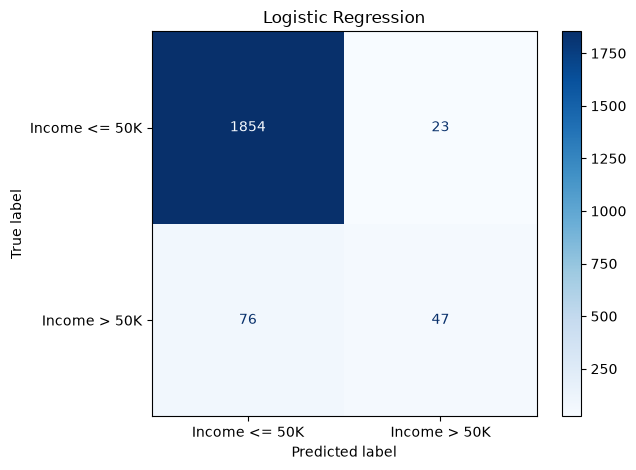

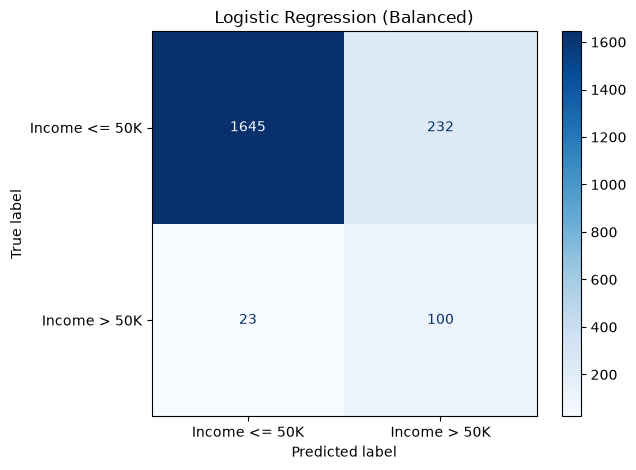

In [71]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

models_predictions = {
    "Majority Classifier": y_pred_majority,
    "Logistic Regression": y_pred_normal,
    "Logistic Regression (Balanced)": y_pred_balanced
}

for model_name, predictions in models_predictions.items():

    cm = confusion_matrix(
        y_val,
        predictions,
        labels=[0, 1]
    )

    display_labels = [
        "Income <= 50K",
        "Income > 50K"
    ]

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=display_labels
    )

    disp.plot(cmap="Blues", values_format="d")

    plt.title(model_name)
    plt.tight_layout()
    plt.show()

<div dir="rtl" style="text-align: right;">
گام چهارم: الگوریتم K-Nearest Neighbors (KNN)
</div>

### 1.

In [72]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import f1_score, recall_score
import pandas as pd
import matplotlib.pyplot as plt

k_values = [3, 5, 9, 15, 21]
weight_methods = ["uniform", "distance"]

knn_results = []
knn_models = {}

for k in k_values:

    for weight in weight_methods:

        knn_model = KNeighborsClassifier(
            n_neighbors=k,
            weights=weight
        )

        knn_model.fit(X_train_processed, y_train)

        y_pred = knn_model.predict(X_val_processed)

        macro_f1 = f1_score(
            y_val,
            y_pred,
            average="macro"
        )

        minority_recall = recall_score(
            y_val,
            y_pred,
            pos_label=1,
            zero_division=0
        )

        knn_results.append({
            "K": k,
            "Weights": weight,
            "Macro-F1": macro_f1,
            "Minority Recall": minority_recall
        })

        knn_models[(k, weight)] = knn_model

### 2 & 3 .

In [73]:
knn_results_df = pd.DataFrame(knn_results)

knn_results_df = knn_results_df.sort_values(
    by=["K", "Weights"]
).reset_index(drop=True)

display(knn_results_df.round(4))

,K,Weights,Macro-F1,Minority Recall
0,3,distance,0.6862,0.3496
1,3,uniform,0.6867,0.3415
2,5,distance,0.7065,0.3577
3,5,uniform,0.7037,0.3496
4,9,distance,0.7004,0.3333
5,9,uniform,0.6968,0.3171
6,15,distance,0.6780,0.2683
7,15,uniform,0.6756,0.2602
8,21,distance,0.6667,0.2358
9,21,uniform,0.6680,0.2358


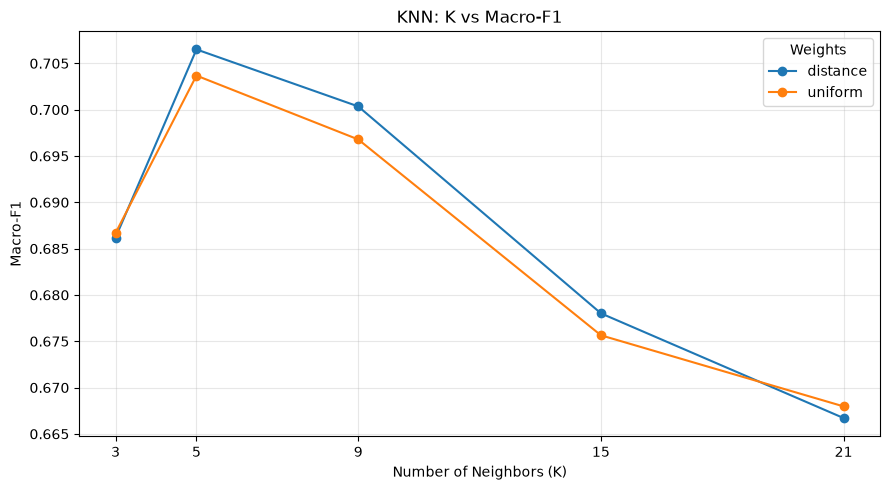

In [74]:
knn_pivot = knn_results_df.pivot(
    index="K",
    columns="Weights",
    values="Macro-F1"
)

knn_pivot.plot(
    marker="o",
    figsize=(9, 5)
)

plt.title("KNN: K vs Macro-F1")
plt.xlabel("Number of Neighbors (K)")
plt.ylabel("Macro-F1")
plt.xticks(k_values)
plt.grid(alpha=0.3)
plt.legend(title="Weights")
plt.tight_layout()
plt.show()

### 4.

In [75]:
best_knn_result = knn_results_df.sort_values(
    by=["Macro-F1", "Minority Recall"],
    ascending=False
).iloc[0]

best_k = int(best_knn_result["K"])
best_weights = best_knn_result["Weights"]

best_knn_model = knn_models[(best_k, best_weights)]

print("Best K:", best_k)
print("Best Weights:", best_weights)

print("Best Macro-F1:", round(best_knn_result["Macro-F1"], 4))
print("Best Minority Recall:", round(best_knn_result["Minority Recall"], 4))

Best K: 5
Best Weights: distance
Best Macro-F1: 0.7065
Best Minority Recall: 0.3577


<div dir="rtl" style="text-align: right;">
  گام پنجم: ماشین بردار پشتیبان (SVM)
</div>

### 1.

In [76]:
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    f1_score,
    balanced_accuracy_score,
    recall_score
)

import pandas as pd
import matplotlib.pyplot as plt
C_values = [0.01, 0.1, 1, 10]

class_weights = [None, "balanced"]

svm_results = []
svm_models = {}

for c in C_values:

    for weight in class_weights:

        svm_model = LinearSVC(
            C=c,
            class_weight=weight,
            max_iter=10000,
            random_state=42
        )

        svm_model.fit(X_train_processed, y_train)

        y_pred = svm_model.predict(X_val_processed)

        macro_f1 = f1_score(
            y_val,
            y_pred,
            average="macro",
            zero_division=0
        )

        balanced_acc = balanced_accuracy_score(
            y_val,
            y_pred
        )

        minority_recall = recall_score(
            y_val,
            y_pred,
            pos_label=1,
            zero_division=0
        )

        svm_results.append({
            "C": c,
            "Class Weight": weight if weight is not None else "None",
            "Macro-F1": macro_f1,
            "Balanced Accuracy": balanced_acc,
            "Minority Recall": minority_recall
        })

        svm_models[(c, weight)] = svm_model

### 2 & 3.

In [77]:
svm_results_df = pd.DataFrame(svm_results)

svm_results_df = svm_results_df.sort_values(
    by=["C", "Class Weight"]
).reset_index(drop=True)

display(svm_results_df.round(4))

,C,Class Weight,Macro-F1,Balanced Accuracy,Minority Recall
0,0.01,None,0.6861,0.6285,0.2602
1,0.01,balanced,0.6651,0.8560,0.8618
2,0.10,None,0.7033,0.6537,0.3171
3,0.10,balanced,0.6775,0.8453,0.8211
4,1.00,None,0.7140,0.6687,0.3496
5,1.00,balanced,0.6739,0.8241,0.7724
6,10.00,None,0.7062,0.6671,0.3496
7,10.00,balanced,0.6726,0.8203,0.7642


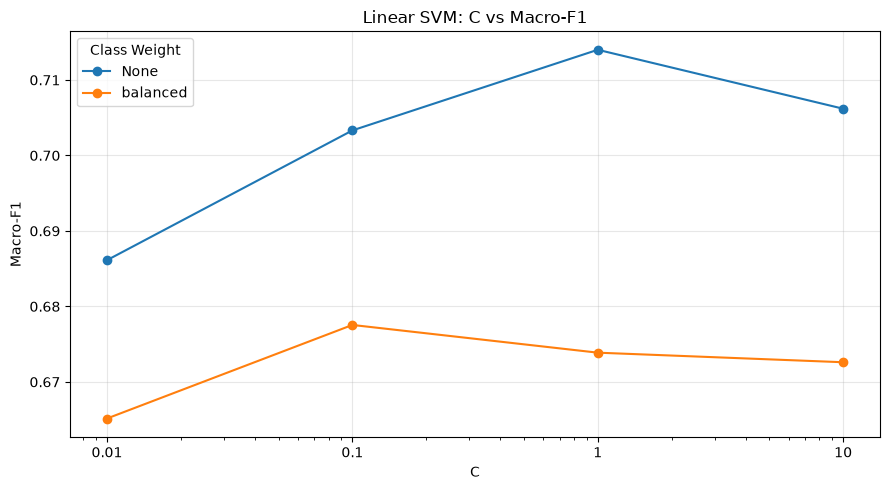

In [78]:
svm_pivot = svm_results_df.pivot(
    index="C",
    columns="Class Weight",
    values="Macro-F1"
)

svm_pivot.plot(
    marker="o",
    figsize=(9, 5)
)

plt.title("Linear SVM: C vs Macro-F1")
plt.xlabel("C")
plt.ylabel("Macro-F1")

plt.xscale("log")
plt.xticks(C_values, labels=C_values)

plt.grid(alpha=0.3)
plt.legend(title="Class Weight")
plt.tight_layout()
plt.show()

In [79]:
best_svm_result = svm_results_df.sort_values(
    by=[
        "Macro-F1",
        "Balanced Accuracy",
        "Minority Recall"
    ],
    ascending=False
).iloc[0]

best_C = best_svm_result["C"]

best_class_weight = (
    None if best_svm_result["Class Weight"] == "None"
    else "balanced"
)

best_svm_model = svm_models[
    (best_C, best_class_weight)
]

print("Best C:", best_C)
print("Best Class Weight:", best_svm_result["Class Weight"])

print("Best Macro-F1:", round(best_svm_result["Macro-F1"], 4))
print("Best Balanced Accuracy:", round(best_svm_result["Balanced Accuracy"], 4))
print("Best Minority Recall:", round(best_svm_result["Minority Recall"], 4))

Best C: 1.0
Best Class Weight: None
Best Macro-F1: 0.714
Best Balanced Accuracy: 0.6687
Best Minority Recall: 0.3496


<div dir="rtl" style="text-align: right;">
گام ششم :Naive Bayes 
</div>

### 1 & 2.

In [80]:
from sklearn.naive_bayes import ComplementNB
from sklearn.preprocessing import OneHotEncoder, KBinsDiscretizer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

from sklearn.metrics import (
    f1_score,
    recall_score,
    classification_report
)
numeric_nb_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),

    ("discretizer", KBinsDiscretizer(
        n_bins=5,
        encode="onehot",
        strategy="quantile"
    ))
])

categorical_nb_pipeline = Pipeline([
    ("imputer", SimpleImputer(
        strategy="constant",
        fill_value="Missing"
    )),

    ("encoder", OneHotEncoder(
        handle_unknown="ignore"
    ))
])

nb_preprocessor = ColumnTransformer([
    ("num", numeric_nb_pipeline, numeric_features),
    ("cat", categorical_nb_pipeline, categorical_features)
])

In [85]:
numeric_nb_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),

    ("discretizer", KBinsDiscretizer(
        n_bins=5,
        encode="onehot",
        strategy="uniform"
    ))
])

categorical_nb_pipeline = Pipeline([
    ("imputer", SimpleImputer(
        strategy="constant",
        fill_value="Missing"
    )),

    ("encoder", OneHotEncoder(
        handle_unknown="ignore"
    ))
])

nb_preprocessor = ColumnTransformer([
    ("num", numeric_nb_pipeline, numeric_features),
    ("cat", categorical_nb_pipeline, categorical_features)
])

In [86]:
nb_X_train = nb_preprocessor.fit_transform(X_train)

nb_X_val = nb_preprocessor.transform(X_val)

print("Training Data Shape:", nb_X_train.shape)
print("Validation Data Shape:", nb_X_val.shape)

Training Data Shape: (8000, 523)
Validation Data Shape: (2000, 523)


### 3 & 4.

In [88]:
alpha_values = [0.1, 1, 5]

nb_results = []
nb_models = {}

for alpha in alpha_values:

    nb_model = ComplementNB(alpha=alpha)

    nb_model.fit(nb_X_train, y_train)

    y_pred = nb_model.predict(nb_X_val)

    macro_f1 = f1_score(
        y_val,
        y_pred,
        average="macro",
        zero_division=0
    )

    recall_class_0 = recall_score(
        y_val,
        y_pred,
        pos_label=0,
        zero_division=0
    )

    recall_class_1 = recall_score(
        y_val,
        y_pred,
        pos_label=1,
        zero_division=0
    )

    nb_results.append({
        "Alpha": alpha,
        "Macro-F1": macro_f1,
        "Recall Class 0": recall_class_0,
        "Recall Class 1": recall_class_1
    })

    nb_models[alpha] = nb_model
    
  

nb_results_df = pd.DataFrame(nb_results)

display(nb_results_df.round(4))

,Alpha,Macro-F1,Recall Class 0,Recall Class 1
0,0.1,0.5590,0.7086,0.9268
1,1.0,0.5407,0.6798,0.9350
2,5.0,0.5348,0.6708,0.9350


In [89]:
for alpha in alpha_values:

    y_pred = nb_models[alpha].predict(nb_X_val)

    print(f"\nComplementNB - Alpha = {alpha}")

    print(classification_report(
        y_val,
        y_pred,
        labels=[0, 1],
        target_names=[
            "Income <= 50K",
            "Income > 50K"
        ],
        zero_division=0
    ))


ComplementNB - Alpha = 0.1
               precision    recall  f1-score   support

Income <= 50K       0.99      0.71      0.83      1877
 Income > 50K       0.17      0.93      0.29       123

     accuracy                           0.72      2000
    macro avg       0.58      0.82      0.56      2000
 weighted avg       0.94      0.72      0.79      2000


ComplementNB - Alpha = 1
               precision    recall  f1-score   support

Income <= 50K       0.99      0.68      0.81      1877
 Income > 50K       0.16      0.93      0.27       123

     accuracy                           0.70      2000
    macro avg       0.58      0.81      0.54      2000
 weighted avg       0.94      0.70      0.77      2000


ComplementNB - Alpha = 5
               precision    recall  f1-score   support

Income <= 50K       0.99      0.67      0.80      1877
 Income > 50K       0.16      0.93      0.27       123

     accuracy                           0.69      2000
    macro avg       0.58      0.

In [90]:
best_nb_result = nb_results_df.sort_values(
    by=["Macro-F1", "Recall Class 1"],
    ascending=False
).iloc[0]

best_alpha = best_nb_result["Alpha"]

best_nb_model = nb_models[best_alpha]

print("Best Alpha:", best_alpha)
print("Best Macro-F1:", round(best_nb_result["Macro-F1"], 4))
print("Minority Recall:", round(best_nb_result["Recall Class 1"], 4))

Best Alpha: 0.1
Best Macro-F1: 0.559
Minority Recall: 0.9268


<div dir="rtl" style="text-align: right;">
 گام هفتم: یادگیری تجمیعی(Ensemble Learning)
</div>

### 1 & 2.

In [91]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    f1_score,
    balanced_accuracy_score,
    recall_score
)
import time
import pandas as pd
import matplotlib.pyplot as plt

results = []
rf_models = {}

dt_model = DecisionTreeClassifier(
    max_depth=10,
    random_state=42
)

start_time = time.perf_counter()
dt_model.fit(X_train_processed, y_train)
dt_time = time.perf_counter() - start_time

dt_pred = dt_model.predict(X_val_processed)

results.append({
    "Model": "Decision Tree",
    "n_estimators": "-",
    "max_depth": 10,
    "class_weight": "None",
    "Training Time (sec)": dt_time,
    "Macro-F1": f1_score(y_val, dt_pred, average="macro"),
    "Balanced Accuracy": balanced_accuracy_score(y_val, dt_pred),
    "Minority Recall": recall_score(y_val, dt_pred, pos_label=1)
})

n_estimators_values = [100, 200, 500]
max_depth_values = [10, 20]
class_weights = [None, "balanced_subsample"]

for n_estimators in n_estimators_values:
    for depth in max_depth_values:
        for weight in class_weights:

            rf_model = RandomForestClassifier(
                n_estimators=n_estimators,
                max_depth=depth,
                class_weight=weight,
                random_state=42,
                n_jobs=-1
            )

            start_time = time.perf_counter()
            rf_model.fit(X_train_processed, y_train)
            training_time = time.perf_counter() - start_time

            rf_pred = rf_model.predict(X_val_processed)

            results.append({
                "Model": "Random Forest",
                "n_estimators": n_estimators,
                "max_depth": depth,
                "class_weight": weight if weight is not None else "None",
                "Training Time (sec)": training_time,
                "Macro-F1": f1_score(y_val, rf_pred, average="macro"),
                "Balanced Accuracy": balanced_accuracy_score(y_val, rf_pred),
                "Minority Recall": recall_score(y_val, rf_pred, pos_label=1)
            })

            rf_models[(n_estimators, depth, weight)] = rf_model


results_df = pd.DataFrame(results)

display(
    results_df.round(4)
)


,Model,n_estimators,max_depth,class_weight,Training Time (sec),Macro-F1,Balanced Accuracy,Minority Recall
0,Decision Tree,-,10,None,0.1193,0.7332,0.7086,0.4390
1,Random Forest,100,10,None,0.2464,0.5234,0.5201,0.0407
2,Random Forest,100,10,balanced_subsample,0.3305,0.6531,0.8469,0.8537
3,Random Forest,100,20,None,0.2827,0.6783,0.6239,0.2520
4,Random Forest,100,20,balanced_subsample,0.4017,0.7350,0.7858,0.6260
5,Random Forest,200,10,None,0.4009,0.5158,0.5160,0.0325
6,Random Forest,200,10,balanced_subsample,0.5988,0.6547,0.8477,0.8537
7,Random Forest,200,20,None,0.5118,0.6834,0.6280,0.2602
8,Random Forest,200,20,balanced_subsample,0.7335,0.7411,0.7942,0.6423
9,Random Forest,500,10,None,0.9726,0.5383,0.5282,0.0569


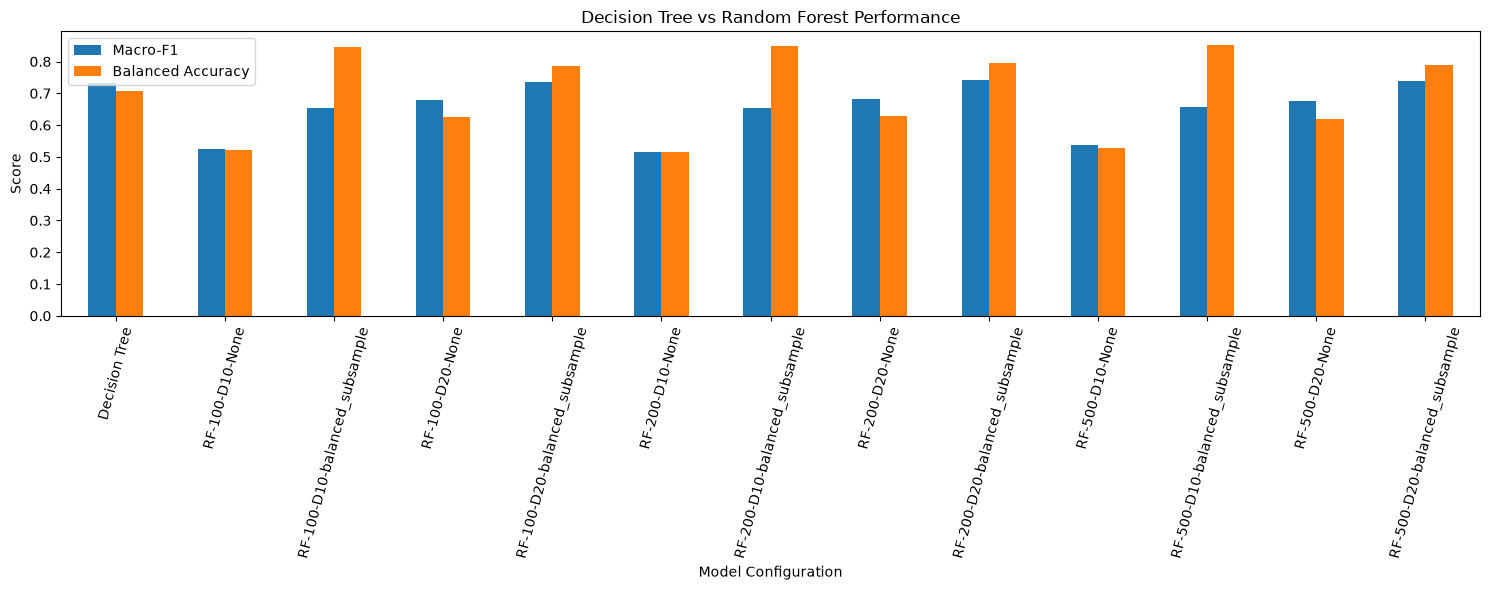

In [92]:
results_df["Configuration"] = results_df.apply(
    lambda row: (
        "Decision Tree"
        if row["Model"] == "Decision Tree"
        else f"RF-{row['n_estimators']}-D{row['max_depth']}-{row['class_weight']}"
    ),
    axis=1
)

results_df.set_index("Configuration")[
    ["Macro-F1", "Balanced Accuracy"]
].plot(
    kind="bar",
    figsize=(15, 6)
)

plt.title("Decision Tree vs Random Forest Performance")
plt.ylabel("Score")
plt.xlabel("Model Configuration")
plt.xticks(rotation=75)
plt.legend()
plt.tight_layout()
plt.show()


### 3.

In [ ]:
rf_results = results_df[
    results_df["Model"] == "Random Forest"
].copy()

weight_comparison = rf_results.pivot(
    index=["n_estimators", "max_depth"],
    columns="class_weight",
    values=["Macro-F1", "Balanced Accuracy", "Minority Recall"]
)

display(weight_comparison.round(4))


Macro-F1                    Balanced Accuracy  \
class_weight               None balanced_subsample              None   
n_estimators max_depth                                                 
100          10          0.5234             0.6531            0.5201   
             20          0.6783             0.7350            0.6239   
200          10          0.5158             0.6547            0.5160   
             20          0.6834             0.7411            0.6280   
500          10          0.5383             0.6574            0.5282   
             20          0.6758             0.7385            0.6204   

                                          Minority Recall                     
class_weight           balanced_subsample            None balanced_subsample  
n_estimators max_depth                                                        
100          10                    0.8469          0.0407             0.8537  
             20                    0.7858          0.2520             0.6260  
200          10                    0.8477          0.0325             0.8537  
             20                    0.7942          0.2602             0.6423  
500          10                    0.8523          0.0569             0.8618  
             20                    0.7902          0.2439             0.6341

### 4.

In [ ]:
final_comparison = results_df[
    [
        "Model",
        "n_estimators",
        "max_depth",
        "class_weight",
        "Training Time (sec)",
        "Macro-F1",
        "Balanced Accuracy",
        "Minority Recall"
    ]
].copy()

final_comparison = final_comparison.sort_values(
    by="Macro-F1",
    ascending=False
)

display(final_comparison.round(4))


,Model,n_estimators,max_depth,class_weight,Training Time (sec),Macro-F1,Balanced Accuracy,Minority Recall
8,Random Forest,200,20,balanced_subsample,0.7335,0.7411,0.7942,0.6423
12,Random Forest,500,20,balanced_subsample,1.7893,0.7385,0.7902,0.6341
4,Random Forest,100,20,balanced_subsample,0.4017,0.7350,0.7858,0.6260
0,Decision Tree,-,10,None,0.1193,0.7332,0.7086,0.4390
7,Random Forest,200,20,None,0.5118,0.6834,0.6280,0.2602
3,Random Forest,100,20,None,0.2827,0.6783,0.6239,0.2520
11,Random Forest,500,20,None,1.2542,0.6758,0.6204,0.2439
10,Random Forest,500,10,balanced_subsample,1.4882,0.6574,0.8523,0.8618
6,Random Forest,200,10,balanced_subsample,0.5988,0.6547,0.8477,0.8537
2,Random Forest,100,10,balanced_subsample,0.3305,0.6531,0.8469,0.8537


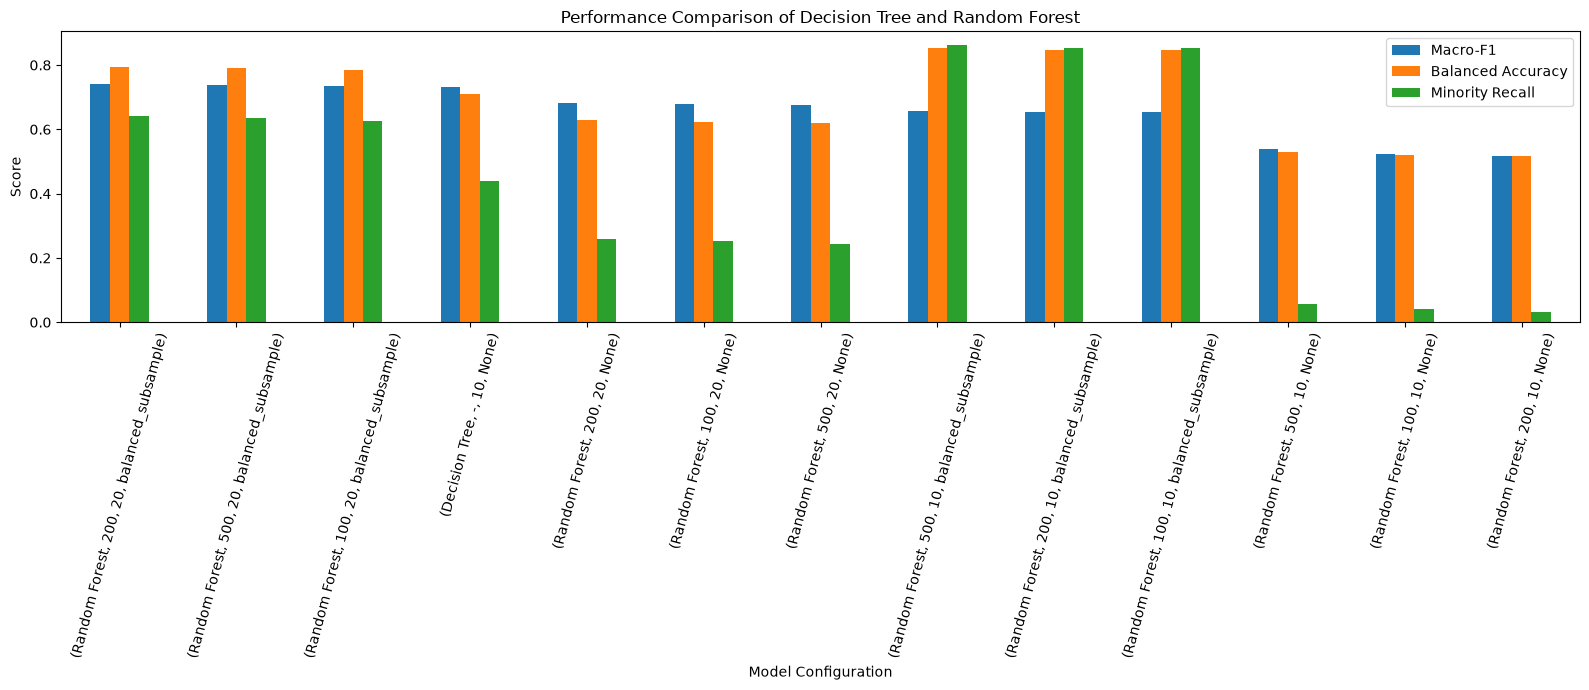

In [96]:
final_comparison.set_index(
    ["Model", "n_estimators", "max_depth", "class_weight"]
)[
    ["Macro-F1", "Balanced Accuracy", "Minority Recall"]
].plot(
    kind="bar",
    figsize=(16, 7)
)

plt.title("Performance Comparison of Decision Tree and Random Forest")
plt.ylabel("Score")
plt.xlabel("Model Configuration")
plt.xticks(rotation=75)
plt.legend()
plt.tight_layout()
plt.show()


### 5.

Best Random Forest Configuration:
Model                                  Random Forest
n_estimators                                     200
max_depth                                         20
class_weight                      balanced_subsample
Training Time (sec)                         0.733466
Macro-F1                                    0.741116
Balanced Accuracy                           0.794234
Minority Recall                             0.642276
Configuration          RF-200-D20-balanced_subsample
Name: 8, dtype: object


,Feature,Importance
0,major occupation code,0.09285
1,detailed occupation recode,0.08518
2,age,0.07149
3,education,0.06437
4,weeks worked in year,0.06267
5,detailed industry recode,0.05887
6,major industry code,0.05410
7,tax filer stat,0.05073
8,dividends from stocks,0.04362
9,sex,0.04353


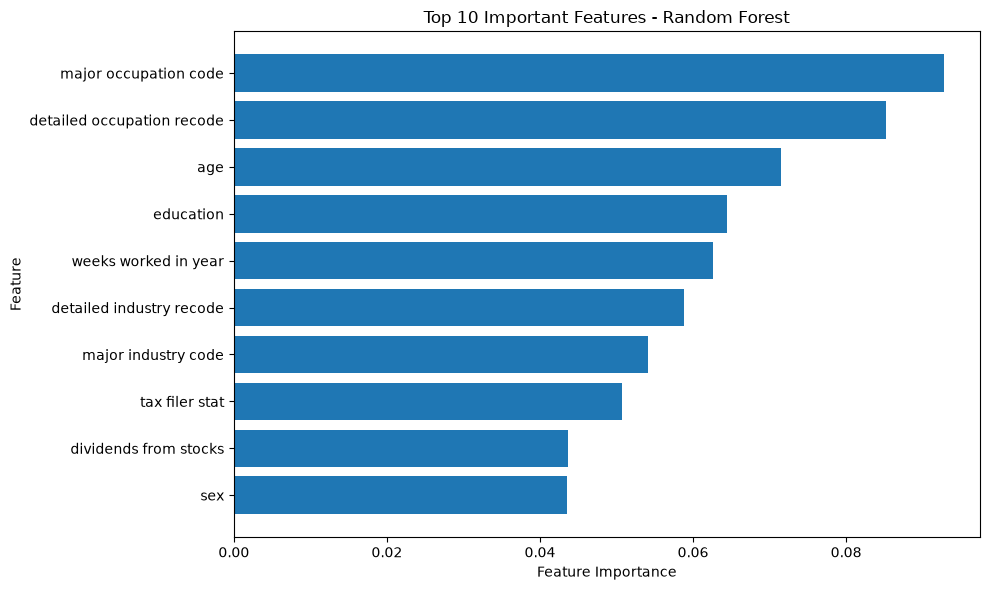

In [97]:
rf_only = results_df[
    results_df["Model"] == "Random Forest"
].copy()

best_rf_row = rf_only.sort_values(
    by=["Macro-F1", "Balanced Accuracy", "Minority Recall"],
    ascending=False
).iloc[0]

best_weight = (
    None if best_rf_row["class_weight"] == "None"
    else best_rf_row["class_weight"]
)

best_key = (
    int(best_rf_row["n_estimators"]),
    int(best_rf_row["max_depth"]),
    best_weight
)

best_rf_model = rf_models[best_key]

print("Best Random Forest Configuration:")
print(best_rf_row)

encoded_feature_names = preprocessor.get_feature_names_out()
encoded_importances = best_rf_model.feature_importances_

feature_importance = {}

for feature in numeric_features:
    indices = [
        i for i, name in enumerate(encoded_feature_names)
        if name == f"num__{feature}"
    ]

    feature_importance[feature] = sum(
        encoded_importances[i] for i in indices
    )


for feature in categorical_features:
    prefix = f"cat__{feature}_"

    indices = [
        i for i, name in enumerate(encoded_feature_names)
        if name.startswith(prefix)
    ]

    feature_importance[feature] = sum(
        encoded_importances[i] for i in indices
    )

importance_df = pd.DataFrame({
    "Feature": list(feature_importance.keys()),
    "Importance": list(feature_importance.values())
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

top_10_features = importance_df.head(10)

display(top_10_features.round(5))

plt.figure(figsize=(10, 6))

plt.barh(
    top_10_features["Feature"].iloc[::-1],
    top_10_features["Importance"].iloc[::-1]
)

plt.title("Top 10 Important Features - Random Forest")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()


<div dir="rtl" style="text-align: right;">
۸ گام هشتم: دسته بندی مبتنی بر قانون(Rule-Based) 
</div>

In [98]:

import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    balanced_accuracy_score,
    recall_score,
    classification_report
)

class OneRClassifier:

    def __init__(self, min_frequency=30):
        self.min_frequency = min_frequency

    def fit(self, X, y, categorical_features):

        X = X.reset_index(drop=True)
        y = pd.Series(y).reset_index(drop=True)

        self.default_class_ = y.value_counts().idxmax()

        feature_errors = {}
        feature_rules = {}
        feature_rare_categories = {}
        feature_rule_tables = {}

        for feature in categorical_features:

            values = X[feature].fillna("Missing").astype(str)

            counts = values.value_counts()
            rare_categories = set(
                counts[counts < self.min_frequency].index
            )

            grouped_values = values.where(
                ~values.isin(rare_categories),
                "Other"
            )

            rules = {}
            rule_rows = []
            total_errors = 0

            for category in pd.unique(grouped_values):

                mask = grouped_values == category
                class_counts = y[mask].value_counts()

                majority_class = class_counts.idxmax()

                errors = int((y[mask] != majority_class).sum())
                total_errors += errors

                rules[category] = majority_class

                rule_rows.append({
                    "Category": category,
                    "Samples": int(mask.sum()),
                    "Predicted Class": majority_class,
                    "Training Errors": errors
                })

            feature_errors[feature] = total_errors / len(y)

            feature_rules[feature] = rules
            feature_rare_categories[feature] = rare_categories
            feature_rule_tables[feature] = pd.DataFrame(rule_rows)

        self.best_feature_ = min(
            feature_errors,
            key=feature_errors.get
        )

        self.rules_ = feature_rules[self.best_feature_]
        self.rare_categories_ = feature_rare_categories[
            self.best_feature_
        ]

        self.training_error_ = feature_errors[self.best_feature_]
        self.rules_table_ = feature_rule_tables[self.best_feature_]

        self.feature_errors_ = pd.DataFrame({
            "Feature": list(feature_errors.keys()),
            "Training Error": list(feature_errors.values())
        }).sort_values(
            by="Training Error"
        ).reset_index(drop=True)

        return self

    def predict(self, X):

        values = X[self.best_feature_].fillna("Missing").astype(str)

        predictions = []

        for value in values:

            if value in self.rare_categories_:
                value = "Other"

            prediction = self.rules_.get(
                value,
                self.default_class_
            )

            predictions.append(prediction)

        return predictions


one_r_model = OneRClassifier(min_frequency=30)

one_r_model.fit(
    X_train,
    y_train,
    categorical_features
)


print("Selected Feature:", one_r_model.best_feature_)
print("Training Error:", round(one_r_model.training_error_, 4))
print("Default Class:", one_r_model.default_class_)

display(one_r_model.feature_errors_.round(4))

print("\nOneR IF-THEN Rules:")

for row in one_r_model.rules_table_.itertuples(index=False):

    print(
        f"IF {one_r_model.best_feature_} == {row.Category} "
        f"THEN income = {row[2]}"
    )

print("\nNumber of rare categories:",
      len(one_r_model.rare_categories_))

print("Rare categories:", sorted(one_r_model.rare_categories_))

print(
    "\nDefault Rule: IF category is unseen, "
    f"THEN income = {one_r_model.default_class_}"
)


Selected Feature: detailed occupation recode
Training Error: 0.0601
Default Class: 0


,Feature,Training Error
0,detailed occupation recode,0.0601
1,class of worker,0.0618
2,detailed industry recode,0.0618
3,education,0.0618
4,enroll in edu inst last wk,0.0618
5,marital stat,0.0618
6,major industry code,0.0618
7,major occupation code,0.0618
8,race,0.0618
9,hispanic origin,0.0618



OneR IF-THEN Rules:
IF detailed occupation recode == 0 THEN income = 0
IF detailed occupation recode == 29 THEN income = 0
IF detailed occupation recode == 23 THEN income = 0
IF detailed occupation recode == 42 THEN income = 0
IF detailed occupation recode == 34 THEN income = 0
IF detailed occupation recode == 10 THEN income = 0
IF detailed occupation recode == Other THEN income = 0
IF detailed occupation recode == 8 THEN income = 0
IF detailed occupation recode == 26 THEN income = 0
IF detailed occupation recode == 3 THEN income = 0
IF detailed occupation recode == 2 THEN income = 0
IF detailed occupation recode == 36 THEN income = 0
IF detailed occupation recode == 44 THEN income = 0
IF detailed occupation recode == 18 THEN income = 0
IF detailed occupation recode == 12 THEN income = 0
IF detailed occupation recode == 35 THEN income = 0
IF detailed occupation recode == 25 THEN income = 0
IF detailed occupation recode == 38 THEN income = 0
IF detailed occupation recode == 17 THEN inc

In [99]:
y_pred_one_r = one_r_model.predict(X_val)

one_r_metrics = {
    "Accuracy": accuracy_score(y_val, y_pred_one_r),
    "Balanced Accuracy": balanced_accuracy_score(y_val, y_pred_one_r),
    "Macro-F1": f1_score(y_val, y_pred_one_r, average="macro"),
    "Minority Recall": recall_score(
        y_val,
        y_pred_one_r,
        pos_label=1,
        zero_division=0
    )
}

one_r_results = pd.DataFrame(
    [one_r_metrics],
    index=["OneR"]
)

display(one_r_results.round(4))

print(classification_report(
    y_val,
    y_pred_one_r,
    labels=[0, 1],
    target_names=["Income <= 50K", "Income > 50K"],
    zero_division=0
))


,Accuracy,Balanced Accuracy,Macro-F1,Minority Recall
OneR,0.9365,0.5331,0.5456,0.0732


               precision    recall  f1-score   support

Income <= 50K       0.94      0.99      0.97      1877
 Income > 50K       0.41      0.07      0.12       123

     accuracy                           0.94      2000
    macro avg       0.68      0.53      0.55      2000
 weighted avg       0.91      0.94      0.92      2000

